# Tarea 2 — Preprocesamiento de datos



## 0. Preparación del entorno

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 1. Carga de datos

In [22]:

from google.colab import drive

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/adult.csv"

df = pd.read_csv(file_path, header=None, sep=";")
print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   0                  1       2           3   4                    5   \
0  39          State-gov   77516   Bachelors  13        Never-married   
1  50   Self-emp-not-inc   83311   Bachelors  13   Married-civ-spouse   
2  38            Private  215646     HS-grad   9             Divorced   
3  53            Private  234721        11th   7   Married-civ-spouse   
4  28            Private  338409   Bachelors  13   Married-civ-spouse   

                   6               7       8        9     10  11  12  \
0        Adm-clerical   Not-in-family   White     Male  2174   0  40   
1     Exec-managerial         Husband   White     Male     0   0  13   
2   Handlers-cleaners   Not-in-family   White     Male     0   0  40   
3   Handlers-cleaners         Husband   Black     Male     0   0  40   
4      Prof-specialty            Wife   Black   Female     0   0  40   


**¿Hay algo extraño?**

In [23]:
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race",
    "sex", "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income"
]

In [24]:
# c.	Explora el dataset: número de filas, columnas, tipos de datos y primeras observaciones.

df.columns = columns

print(f"Dimensiones del dataset (filas, columnas): {df.shape}\n")
print("Información general y tipos de datos:")
df.info()

print("\nPrimeras observaciones:")
display(df.head())

Dimensiones del dataset (filas, columnas): (32561, 15)

Información general y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Limpieza de datos

In [25]:
# a) Identificar valores faltantes (en este dataset se marcan como "?")

for col in df.columns:
    if (df[col] == " ?").any():
        print(f"Columna '{col}' contiene '?'")

Columna 'workclass' contiene '?'
Columna 'occupation' contiene '?'
Columna 'native_country' contiene '?'


In [26]:
# b) Sustituir los '?' por NaN
df = df.replace(" ?", np.nan)
for col in df.columns:
    if (df[col] == " ?").any():
        print(f"Columna '{col}' contiene '?'")

In [27]:
# c) Calcular cuántos valores faltantes hay por columna
missing_counts = df.isna().sum()
print("\nValores faltantes por columna:\n", missing_counts)


Valores faltantes por columna:
 age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [28]:
# d) Estrategias de imputación o eliminación:
# 1. Eliminar filas con NaN → solo si el % de faltantes es muy bajo (<5%).

df_sin_nulos = df.dropna()
print("Tamaño del dataset después de eliminar filas con NaN:", df_sin_nulos.shape)

# 2. Imputar valores faltantes en columnas categóricas:
#   - Usar la moda (categoría más frecuente).

columnas_categoricas = df.select_dtypes(include=['object']).columns

for col in columnas_categoricas:
    if df[col].isna().any():
        moda = df[col].mode()[0]
        df[col] = df[col].fillna(moda)
        print(f"Los valores faltantes de la columna '{col}' se rellenaron con: {moda}")

# 3. Imputar valores faltantes en columnas numéricas (si hubiera):
#   - Usar la mediana o la media.

columnas_numericas = df.select_dtypes(include=['int64', 'float64']).columns

for col in columnas_numericas:
    if df[col].isna().any():
        mediana = df[col].median()
        df[col] = df[col].fillna(mediana)
        print(f"Los valores faltantes de la columna '{col}' se rellenaron con la mediana: {mediana}")

Tamaño del dataset después de eliminar filas con NaN: (30162, 15)
Los valores faltantes de la columna 'workclass' se rellenaron con:  Private
Los valores faltantes de la columna 'occupation' se rellenaron con:  Prof-specialty
Los valores faltantes de la columna 'native_country' se rellenaron con:  United-States


## 3.	Tratamiento de variables categóricas

### One-Hot Encoding (OHE)

*   ¿Qué hace?: crea una columna binaria (0/1) por cada categoría.

    * Ejemplo: sex = ["Male", "Female"] → sex_Male, sex_Female.

*   ¿Cuándo usarlo?:

    * Variables nominales (categorías sin orden): sexo, color, país.

    * Modelos lineales (Regresión Logística, SVM, Redes Neuronales), porque no deben interpretar un orden ficticio.

    * Evita sesgos: no se asigna ningún “peso ordinal” a las categorías.

*   Inconveniente:

    * Aumenta mucho la dimensionalidad si hay muchas categorías (ej. native_country).

### Label Encoding (LE)

*   ¿Qué hace?: asigna un número entero a cada categoría.
    * Ejemplo: education = ["Bachelors", "Masters", "PhD"] → 0, 1, 2.

*   ¿Cuándo usarlo?:

    * Variables ordinales (con orden natural): nivel educativo, categoría de producto (bajo, medio, alto).

    * Modelos basados en árboles de decisión (Decision Trees, Random Forest, XGBoost, LightGBM), porque los árboles no interpretan el valor numérico como orden, solo lo usan para dividir.

*   Inconveniente:

    * En modelos lineales, puede introducir un orden ficticio. Ejemplo: Rojo=0, Verde=1, Azul=2 → el modelo podría asumir que “Azul > Verde > Rojo”, lo cual no tiene sentido.

In [29]:
# a.	Identifica las variables categóricas del dataset.
# Identificar columnas categóricas

columnas_categoricas = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Las variables categóricas del dataset son:\n")
for col in columnas_categoricas:
    print(f"- {col}")

Las variables categóricas del dataset son:

- workclass
- education
- marital_status
- occupation
- relationship
- race
- sex
- native_country
- income


In [30]:
# b.	Convierte estas variables en formato numérico utilizando técnicas como:
#  One-hot encoding

columnas_nominales = ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

df = pd.get_dummies(df, columns=columnas_nominales, dtype=int)

print(f"La nueva forma del dataset (filas, columnas) es: {df.shape}")
print("\nPrimeras filas mostrando las nuevas columnas creadas:")
print(df.head())

La nueva forma del dataset (filas, columnas) es: (32561, 91)

Primeras filas mostrando las nuevas columnas creadas:
   age  fnlwgt   education  education_num  capital_gain  capital_loss  \
0   39   77516   Bachelors             13          2174             0   
1   50   83311   Bachelors             13             0             0   
2   38  215646     HS-grad              9             0             0   
3   53  234721        11th              7             0             0   
4   28  338409   Bachelors             13             0             0   

   hours_per_week  income  workclass_ Federal-gov  workclass_ Local-gov  ...  \
0              40   <=50K                       0                     0  ...   
1              13   <=50K                       0                     0  ...   
2              40   <=50K                       0                     0  ...   
3              40   <=50K                       0                     0  ...   
4              40   <=50K                    

In [31]:
# Label encoding

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()


if 'education' in df.columns:
    df['education'] = le.fit_transform(df['education'])

if 'income' in df.columns:
    df['income'] = le.fit_transform(df['income'])

print("Variables 'education' e 'income' transformadas a números enteros:\n")
print(df[['education', 'income']].head(10))

Variables 'education' e 'income' transformadas a números enteros:

   education  income
0          9       0
1          9       0
2         11       0
3          1       0
4          9       0
5         12       0
6          6       0
7         11       1
8         12       1
9          9       1


## 4.	Tratamiento de variables numéricas

In [32]:
# Identificar variables numéricas
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Las variables numéricas del dataset son:")
print(num_cols)

Las variables numéricas del dataset son:
['age', 'fnlwgt', 'education', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'income', 'workclass_ Federal-gov', 'workclass_ Local-gov', 'workclass_ Never-worked', 'workclass_ Private', 'workclass_ Self-emp-inc', 'workclass_ Self-emp-not-inc', 'workclass_ State-gov', 'workclass_ Without-pay', 'marital_status_ Divorced', 'marital_status_ Married-AF-spouse', 'marital_status_ Married-civ-spouse', 'marital_status_ Married-spouse-absent', 'marital_status_ Never-married', 'marital_status_ Separated', 'marital_status_ Widowed', 'occupation_ Adm-clerical', 'occupation_ Armed-Forces', 'occupation_ Craft-repair', 'occupation_ Exec-managerial', 'occupation_ Farming-fishing', 'occupation_ Handlers-cleaners', 'occupation_ Machine-op-inspct', 'occupation_ Other-service', 'occupation_ Priv-house-serv', 'occupation_ Prof-specialty', 'occupation_ Protective-serv', 'occupation_ Sales', 'occupation_ Tech-support', 'occupation_ Transport-moving

In [33]:
# b) Escalado estándar (z-score) y Min-Max normalization

from sklearn.preprocessing import StandardScaler, MinMaxScaler

df_zscore = df.copy()
df_minmax = df.copy()


scaler_z = StandardScaler()
df_zscore[num_cols] = scaler_z.fit_transform(df[num_cols])

scaler_minmax = MinMaxScaler()
df_minmax[num_cols] = scaler_minmax.fit_transform(df[num_cols])

print("--- Comparativa de la columna 'age' ---")
print("Original:")
print(df['age'].head())
print("\nCon Escalado Estándar (Z-Score):")
print(df_zscore['age'].head())
print("\nCon Normalización Min-Max:")
print(df_minmax['age'].head())

--- Comparativa de la columna 'age' ---
Original:
0    39
1    50
2    38
3    53
4    28
Name: age, dtype: int64

Con Escalado Estándar (Z-Score):
0    0.030671
1    0.837109
2   -0.042642
3    1.057047
4   -0.775768
Name: age, dtype: float64

Con Normalización Min-Max:
0    0.301370
1    0.452055
2    0.287671
3    0.493151
4    0.150685
Name: age, dtype: float64


### ¿Qué técnica conviene más?

Si usamos árboles de decisión (Random Forest, XGBoost, etc.), no es necesario escalar.

Si usamos modelos lineales, SVM, KNN o redes neuronales, conviene escalar:

*    Z-score: útil si los datos tienen distribución similar a la normal.
*    Min-Max: útil cuando el modelo espera datos en un rango fijo (ej. [0,1]).


## 5.	Detección y tratamiento de outliers

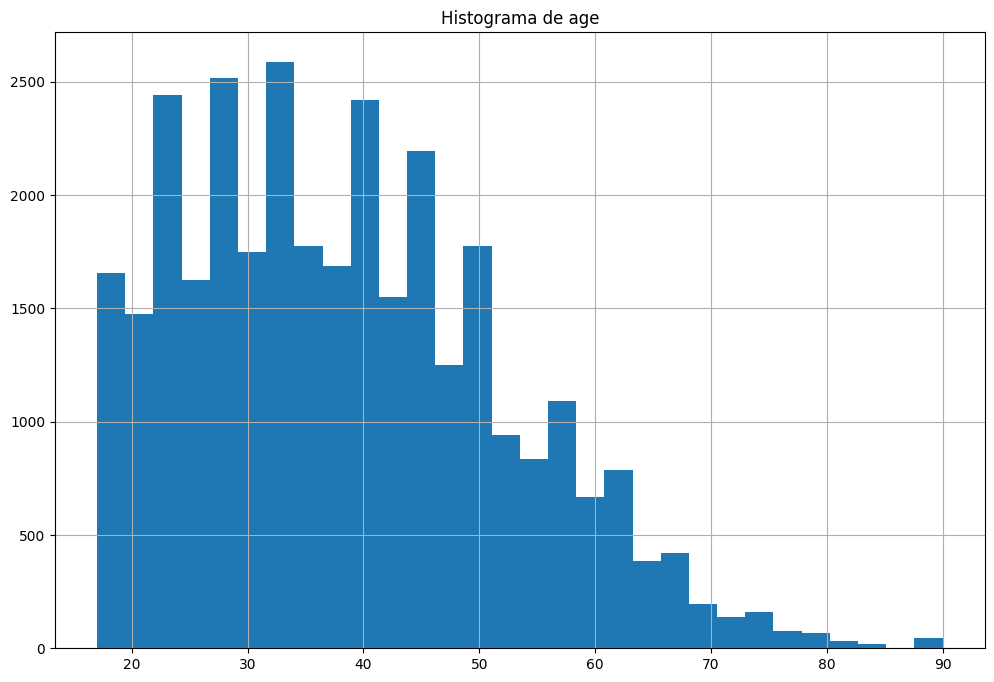

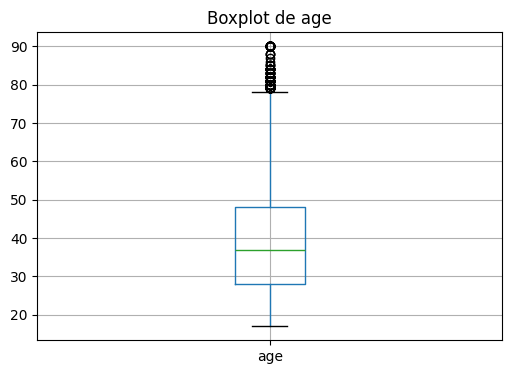

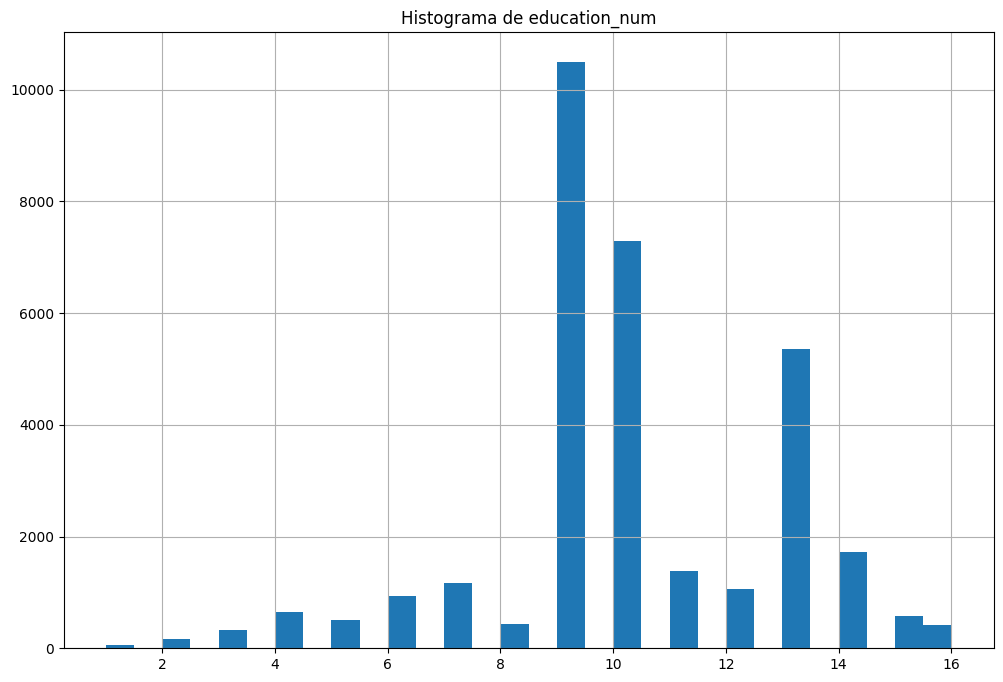

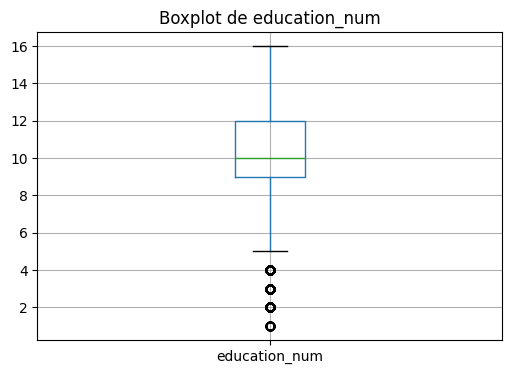

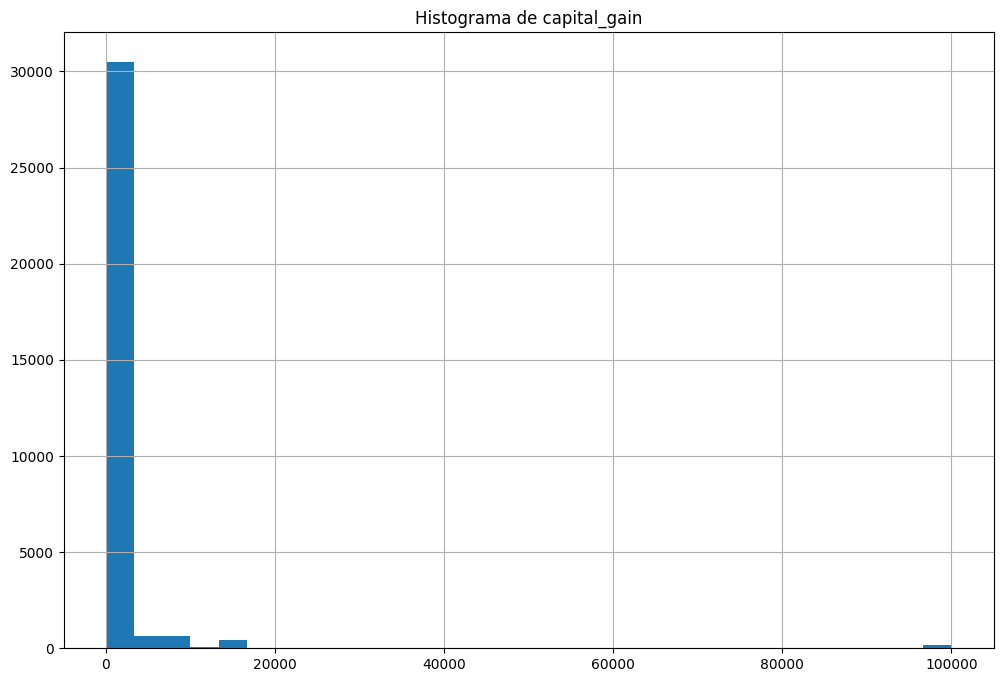

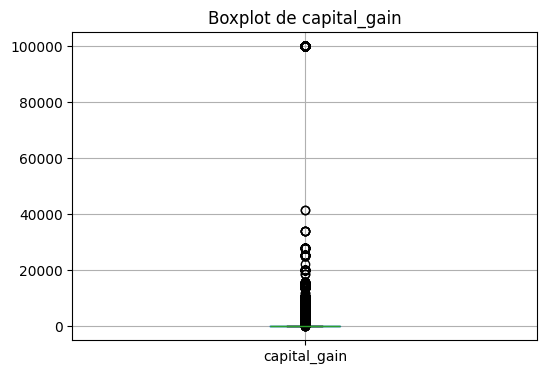

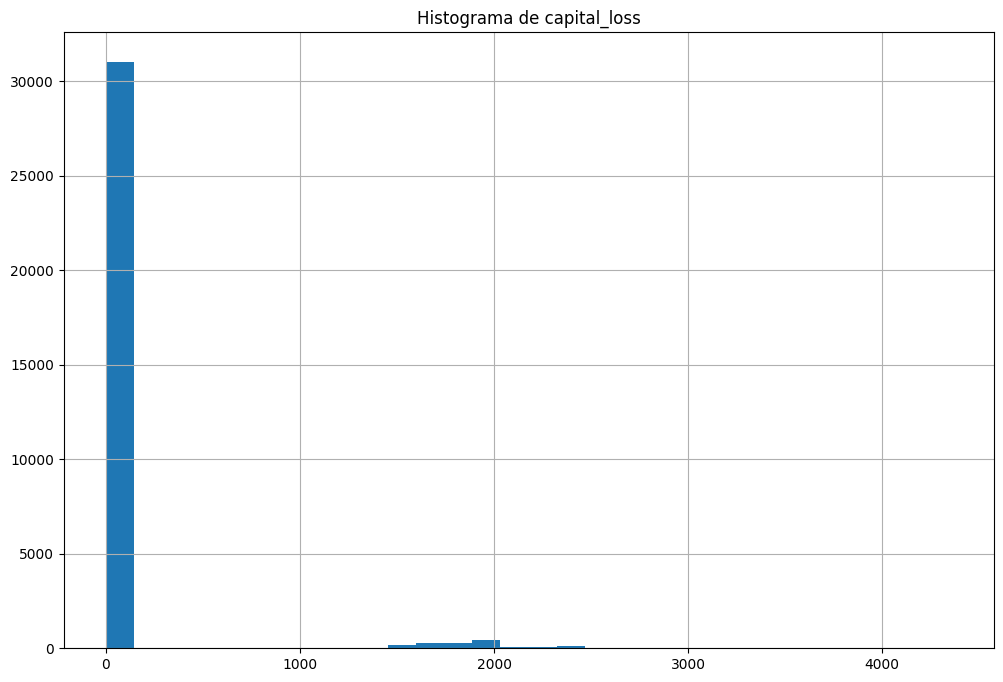

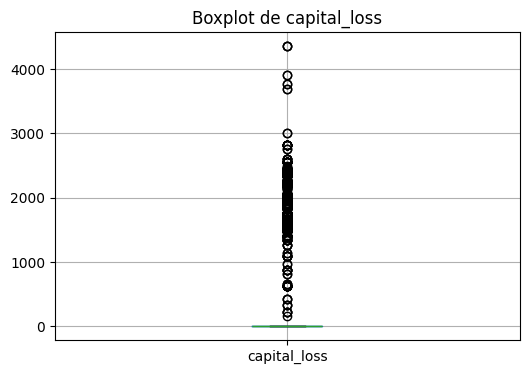

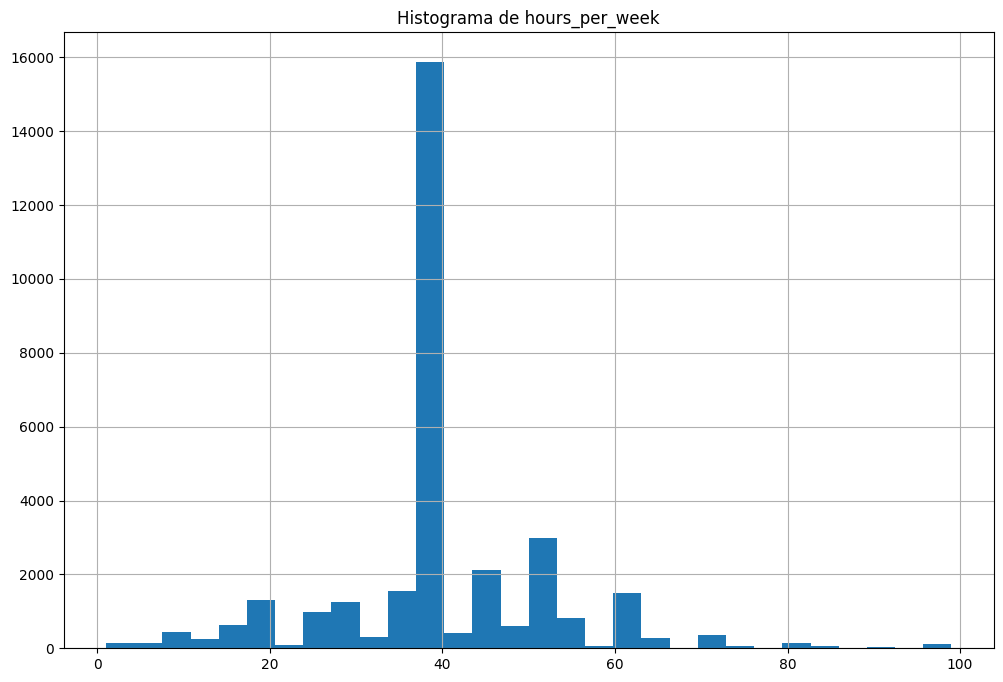

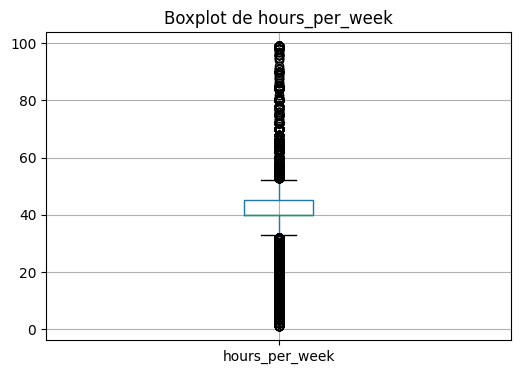

In [34]:
#1. Visualiza la distribución de variables numéricas con histogramas y boxplots.

import matplotlib.pyplot as plt

num_cols = ["age", "education_num",
            "capital_gain", "capital_loss", "hours_per_week"]

for col in num_cols:
    # Histograma
    df[col].hist(bins=30, figsize=(12,8))
    plt.title(f"Histograma de {col}")
    plt.show()

    # Boxplot
    plt.figure(figsize=(6,4))
    df.boxplot(column=col)
    plt.title(f"Boxplot de {col}")
    plt.show()

In [35]:
# 2. Identifica posibles outliers (ej. horas trabajadas por semana, edad).
# hours_per_week: valores muy altos (ej. >80 horas) son poco frecuentes.
# age: aparecen algunos casos extremos (mayores de 90 años).
# capital_gain y capital_loss: la mayoría son 0, pero hay valores muy grandes.


outliers_horas = df[df['hours_per_week'] > 80]
print(f"Hay {outliers_horas.shape[0]} personas trabajando más de 80 horas por semana.")

outliers_edad = df[df['age'] >= 90]
print(f"Hay {outliers_edad.shape[0]} personas con 90 años o más.")

ceros_gain = (df['capital_gain'] == 0).sum()
ceros_loss = (df['capital_loss'] == 0).sum()
total_filas = df.shape[0]

print(f"En 'capital_gain', {ceros_gain} de {total_filas} registros son cero ({(ceros_gain/total_filas)*100:.1f}%).")
print(f"En 'capital_loss', {ceros_loss} de {total_filas} registros son cero ({(ceros_loss/total_filas)*100:.1f}%).")

print("\nLos 5 valores más grandes de 'capital_gain':", df['capital_gain'].nlargest(5).values)
print("Los 5 valores más grandes de 'capital_loss':", df['capital_loss'].nlargest(5).values)

Hay 208 personas trabajando más de 80 horas por semana.
Hay 43 personas con 90 años o más.
En 'capital_gain', 29849 de 32561 registros son cero (91.7%).
En 'capital_loss', 31042 de 32561 registros son cero (95.3%).

Los 5 valores más grandes de 'capital_gain': [99999 99999 99999 99999 99999]
Los 5 valores más grandes de 'capital_loss': [4356 4356 4356 3900 3900]


### Clipping
  * Es recortar los valores extremos de una variable a un límite superior e inferior.
  * Ejemplo:
    
     Si hours_per_week tiene valores desde 1 a 99, pero definimos que lo “normal” es entre 10 y 80:
     
     5 → se convierte en 10
     
     90 → se convierte en 80

### Winsorización

 * Es una forma más controlada de clipping que sustituye los valores extremos por ciertos percentiles de la distribución.

 * Ejemplo:

    Los valores por debajo del percentil 1 se sustituyen por el valor del percentil 1.

    Los valores por encima del percentil 99 se sustituyen por el valor del percentil 99.

In [36]:
# 3. Aplica técnicas de recorte (clipping), winsorización o eliminación.


from scipy.stats.mstats import winsorize

# Clipping

df_clipping = df.copy()
df_clipping['hours_per_week'] = df_clipping['hours_per_week'].clip(lower=10, upper=80)

print("--- CLIPPING ('hours_per_week') ---")
print("Máximo original:", df['hours_per_week'].max())
print("Máximo tras Clipping:", df_clipping['hours_per_week'].max())
print("Mínimo original:", df['hours_per_week'].min())
print("Mínimo tras Clipping:", df_clipping['hours_per_week'].min())


# Winsorize

df_winsorize = df.copy()
df_winsorize['age'] = winsorize(df_winsorize['age'], limits=[0.01, 0.01])

print("\n--- WINSORIZACIÓN ('age') ---")
print("Edad máxima original:", df['age'].max())
print("Edad máxima tras Winsorización (percentil 99):", df_winsorize['age'].max())

# Eliminacion


df_eliminacion = df.copy()

df_eliminacion = df_eliminacion[df_eliminacion['age'] < 90]

print("\n--- ELIMINACIÓN ('age') ---")
print("Total de filas original:", df.shape[0])
print("Total de filas tras eliminar edades >= 90:", df_eliminacion.shape[0])

--- CLIPPING ('hours_per_week') ---
Máximo original: 99
Máximo tras Clipping: 80
Mínimo original: 1
Mínimo tras Clipping: 10

--- WINSORIZACIÓN ('age') ---
Edad máxima original: 90
Edad máxima tras Winsorización (percentil 99): 74

--- ELIMINACIÓN ('age') ---
Total de filas original: 32561
Total de filas tras eliminar edades >= 90: 32518


## 6.	Balanceo de clases


--- Conteo total de cada clase ---
income
0    24720
1     7841
Name: count, dtype: int64

--- Proporción de cada clase (%) ---
income
0    75.919044
1    24.080956
Name: proportion, dtype: float64


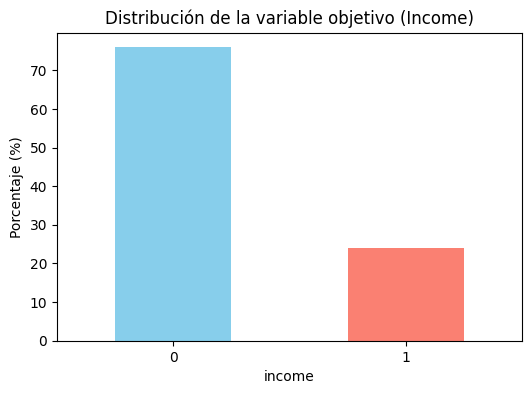

In [37]:
# a.	Calcula la proporción de clases en la variable objetivo ('<=50K' vs '>50K')

import matplotlib.pyplot as plt

conteo_clases = df['income'].value_counts()
print("--- Conteo total de cada clase ---")
print(conteo_clases)

proporcion_clases = df['income'].value_counts(normalize=True) * 100
print("\n--- Proporción de cada clase (%) ---")
print(proporcion_clases)

proporcion_clases.plot(kind='bar', color=['skyblue', 'salmon'], figsize=(6,4))
plt.title('Distribución de la variable objetivo (Income)')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.show()

### Undersampling
* Reduce el número de ejemplos de la clase mayoritaria hasta igualarlo con la clase minoritaria
  * A favor: simple y rápido
  * En contra: pierdes información
### Oversampling
* Aumenta el número de ejemplos de la clase minoritaria duplicando ejemplos
 existentes.
  * A favor: conservas los datos
  * En contra: riesgo de sobreajuste
### SMOTE
* Genera ejemplos sintéticos nuevos para la clase minoritaria interpolando entre instancias reales.
  * A favor: datos más variados y menos sobreajuste
  * En contra: puede crear ruido si hay outliers

### ¿Balancear o no?
  * Depende
    * Si quieres mejorar la detección de la clase minoritaria
    * Cuando utilizamos modelos sensibles al desbalanceo:
      * RL
      * RNN
      * KNN
      * SVM


In [38]:
# b.	Aplica técnicas para balancear

from sklearn.utils import resample
import pandas as pd

df_majority = df[df["income"] == 0]
df_minority = df[df["income"] == 1]

df_majority_down = resample(df_majority,
                            replace=False,
                            n_samples=len(df_minority),
                            random_state=42)

df_under = pd.concat([df_majority_down, df_minority])

print("--- Undersampling ---")
print(df_under["income"].value_counts(normalize=True))

# Submuestreo (undersampling)
df_minority_up = resample(df_minority,
                          replace=True,
                          n_samples=len(df_majority),
                          random_state=42)

df_over = pd.concat([df_majority, df_minority_up])

print("\n--- Oversampling ---")
print(df_over["income"].value_counts(normalize=True))

# Sobremuestreo (oversampling)
from imblearn.over_sampling import SMOTE

X = df.drop(columns=["income"])
y = df["income"]
# SMOTE
X_enc = pd.get_dummies(X, drop_first=True)

smote = SMOTE(random_state=42)
X_sm, y_sm = smote.fit_resample(X_enc, y)

print("\n--- SMOTE ---")
print(y_sm.value_counts(normalize=True))

--- Undersampling ---
income
0    0.5
1    0.5
Name: proportion, dtype: float64

--- Oversampling ---
income
0    0.5
1    0.5
Name: proportion, dtype: float64

--- SMOTE ---
income
0    0.5
1    0.5
Name: proportion, dtype: float64


## 7.	División de datos

### a) Divide el dataset en conjuntos de entrenamiento y prueba

La idea es separar los datos en dos subconjuntos:
- **Train (entrenamiento)**: para ajustar el modelo.
- **Test (prueba)**: para evaluar el rendimiento en datos nuevos.

In [39]:
#a.	 Divide el dataset en conjuntos de entrenamiento y prueba.
# División 80/20
#b.	Asegúrate de que la división mantiene la proporción de clases (stratified split).

from sklearn.model_selection import train_test_split

X = df.drop('income', axis=1)
y = df['income']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (26048, 90)
Dimensiones de X_test: (6513, 90)
